# CS770 Visual Quality Inspection

## Team members

- Supriya Gurung
- Jennifer Isobe
- Sydney Epke

## How to run

Install the packages listed in requirements.txt and select that
Python environment as the notebook kernel.

Place the original dataset in data/casting_512x512/, with
def_front and ok_front directly inside that folder. To use a
different location, set the CASTING_DATA_DIR environment variable
to the folder that contains def_front and ok_front before starting
Jupyter, for example:

    export CASTING_DATA_DIR=/path/to/casting_512x512

Run this notebook from the repository root. Restart the kernel and
run all cells in order. The audit and split cells reproduce the
fixed split using seed 770 and check it against the saved files in
splits/; they stop with an error if the data does not match.
Model-loading cells use the saved split manifest.

## Dataset

Ravirajsinh Dabhi, *Casting Product Image Data for Quality Inspection*, Kaggle:
https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product

We use only the original casting_512x512 collection (1,300 top-view photographs
of cast submersible pump impellers), not the larger, already-augmented
casting_data collection. The images are not included with this notebook. They
are used under the terms posted on the dataset page.

## Contents

1. Setup and environment
2. Data preparation: audit, stratified split, preprocessing
3. Logistic regression baseline
4. CNN and controlled experiment (dropout 0.0 vs. 0.25)
5. Validation-based model selection
6. Test evaluation and error analysis (selected model, evaluated once)
7. Discussion, limitations, and conclusions

## Setup and environment

The next cell imports all packages and records the environment: operating system,
Python and package versions, PyTorch device, and random seed. It also checks that
the dataset folder is in place.

In [1]:
import hashlib
import os
import platform
import sys
import time
import warnings
from functools import partial
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import sklearn
import torch
from PIL import Image
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score,
)
from sklearn.model_selection import train_test_split

SEED = 770  # used for the split; CNN runs reset their seeds with it before training

# Same rule as the CNN section: CUDA if available, otherwise CPU.
# Apple MPS is not used, to keep CNN results reproducible.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Environment")
print("  Operating system:", platform.platform())
print("  Python:", sys.version.split()[0])
for package_name, module in [
    ("numpy", np), ("pandas", pd), ("scikit-learn", sklearn),
    ("Pillow", PIL), ("matplotlib", matplotlib), ("torch", torch),
]:
    print(f"  {package_name}: {module.__version__}")
print("  PyTorch device:", device)
print("  Random seed:", SEED)

# Data location: set CASTING_DATA_DIR to override the default.
DATA_DIR = Path(os.environ.get("CASTING_DATA_DIR", Path("data") / "casting_512x512"))
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("\nDataset folder:",
      "set by CASTING_DATA_DIR" if "CASTING_DATA_DIR" in os.environ
      else DATA_DIR.as_posix())

for class_name in ["def_front", "ok_front"]:
    folder = DATA_DIR / class_name
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Missing folder {class_name}/ inside the dataset folder. Put def_front/ "
            "and ok_front/ in data/casting_512x512/, or set CASTING_DATA_DIR."
        )
    images = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    print(f"{class_name}: {len(images)} image files")

Environment
  Operating system: macOS-27.0.1-arm64-arm-64bit
  Python: 3.12.14
  numpy: 2.5.5
  pandas: 3.1.1
  scikit-learn: 1.9.1
  Pillow: 13.0.0
  matplotlib: 3.11.2
  torch: 2.15.0
  PyTorch device: cpu
  Random seed: 770

Dataset folder: data/casting_512x512
def_front: 781 image files
ok_front: 519 image files


## Data preparation

### Data audit

The next cell reads every image and records its size and color mode. It also hashes
the decoded pixels to find exact duplicate images and any duplicates with
conflicting labels.

In [2]:
LABEL_MAP = {"ok_front": 0, "def_front": 1}

records = []
unreadable = []

for class_name, label in LABEL_MAP.items():
    folder = DATA_DIR / class_name

    for path in sorted(folder.iterdir()):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative_path = path.relative_to(DATA_DIR).as_posix()

        try:
            with Image.open(path) as image:
                image.load()
                width, height = image.size
                original_mode = image.mode

                # Compare decoded pixel content, not filenames or file metadata.
                rgb_image = image.convert("RGB")
                digest = hashlib.sha256()
                digest.update(f"{width}x{height}|RGB|".encode())
                digest.update(rgb_image.tobytes())

            records.append({
                "relative_path": relative_path,
                "class_name": class_name,
                "label": label,
                "width": width,
                "height": height,
                "original_mode": original_mode,
                "content_hash": digest.hexdigest(),
            })

        except Exception as error:
            unreadable.append({
                "relative_path": relative_path,
                "reason": str(error),
            })

audit_df = pd.DataFrame(records)
unreadable_df = pd.DataFrame(
    unreadable, columns=["relative_path", "reason"]
)

assert not audit_df.empty, "No readable images found. Check DATA_DIR."

duplicate_rows = audit_df[
    audit_df.duplicated("content_hash", keep=False)
].sort_values(["content_hash", "relative_path"])

label_counts = audit_df.groupby("content_hash")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index

print("Readable images:", len(audit_df))
print("Unreadable images:", len(unreadable_df))

print("\nImage dimensions:")
print(
    audit_df.groupby(["width", "height"])
    .size()
    .rename("count")
    .to_string()
)

print("\nReadable images by class:")
print(audit_df["class_name"].value_counts().to_string())

print("\nDuplicate content groups:", duplicate_rows["content_hash"].nunique())
print("Images in duplicate groups:", len(duplicate_rows))
print("Groups with conflicting labels:", len(conflicting_hashes))

if not unreadable_df.empty:
    display(unreadable_df)

if not duplicate_rows.empty:
    display(
        duplicate_rows[
            ["relative_path", "label", "content_hash"]
        ]
    )

Readable images: 1300
Unreadable images: 0

Image dimensions:
width  height
512    512       1300

Readable images by class:
class_name
def_front    781
ok_front     519

Duplicate content groups: 0
Images in duplicate groups: 0
Groups with conflicting labels: 0


### Audit results

The original casting_512x512 collection contains exactly 1,300 images: 781 are defective and 519 are acceptable. All images were readable and had the dimensions of 512 x 512 pixels. Comparing the decoded RGB pixel content found no exact duplicate images or conflicting-label duplicates. No images were excluded based on these checks.

Labels: acceptable = 0; defective = 1.

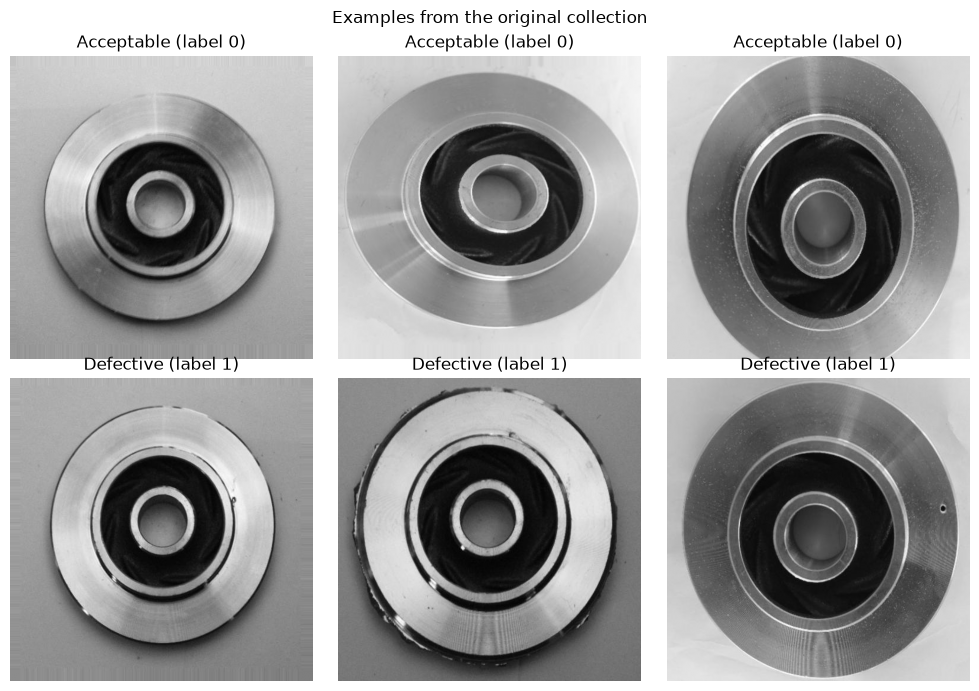

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for row_index, class_name in enumerate(["ok_front", "def_front"]):
    samples = audit_df[
        audit_df["class_name"] == class_name
    ].sample(n=3, random_state=770)

    for ax, (_, row) in zip(axes[row_index], samples.iterrows()):
        with Image.open(DATA_DIR / row["relative_path"]) as image:
            ax.imshow(image.convert("L"), cmap="gray")

        label_name = "Defective" if row["label"] == 1 else "Acceptable"
        ax.set_title(f"{label_name} (label {row['label']})")
        ax.axis("off")

plt.suptitle("Examples from the original collection")
plt.tight_layout()
plt.show()

### Stratified split

The audited images are split into 70% training, 15% validation, and 15% test,
stratified by class, with random seed 770. The second cell checks the split against
the saved files in splits/ and prints every filename in each split.

In [4]:
# Every audited image passed our checks.
# Sort first so the starting order is reproducible.
clean_df = audit_df.sort_values("relative_path").reset_index(drop=True)

# Reserve 30% for validation + test.
train_df, remaining_df = train_test_split(
    clean_df,
    test_size=0.30,
    stratify=clean_df["label"],
    random_state=SEED,
)

# Divide that reserved portion equally.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["label"],
    random_state=SEED,
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

split_manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
).sort_values(["split", "relative_path"]).reset_index(drop=True)

# Verify every image appears exactly once.
assert len(split_manifest) == len(clean_df)
assert split_manifest["relative_path"].is_unique
assert split_manifest["content_hash"].is_unique

split_counts = pd.crosstab(
    split_manifest["split"],
    split_manifest["label"],
).reindex(["train", "validation", "test"])

split_counts = split_counts.rename(
    columns={0: "Acceptable (0)", 1: "Defective (1)"}
)
split_counts["Total"] = split_counts.sum(axis=1)

display(split_counts)

label,Acceptable (0),Defective (1),Total
split,,,
train,363,547,910
validation,78,117,195
test,78,117,195


In [5]:
SPLIT_DIR = Path("splits")
SPLIT_DIR.mkdir(exist_ok=True)

# Set to True only if the team agrees to replace the shared split files.
REBUILD_SPLIT_FILES = False

split_files = {
    "image_audit.csv": audit_df,
    "unreadable_images.csv": unreadable_df,
    "split_manifest.csv": split_manifest[
        ["relative_path", "label", "split", "content_hash"]
    ],
}

for file_name, table in split_files.items():
    file_path = SPLIT_DIR / file_name
    table = table.reset_index(drop=True)

    if REBUILD_SPLIT_FILES or not file_path.exists():
        table.to_csv(file_path, index=False)
        print(f"Wrote {file_path.as_posix()}")
        continue

    saved = pd.read_csv(file_path)
    try:
        pd.testing.assert_frame_equal(
            saved.astype(str), table.astype(str), check_dtype=False,
        )
    except AssertionError as difference:
        raise RuntimeError(
            f"{file_path.as_posix()} does not match this run. Check that DATA_DIR "
            "holds the original casting_512x512 images. The saved file was not changed."
        ) from difference
    print(f"Matches saved file: {file_path.as_posix()}")

# Print the complete filename lists into the notebook output,
# as required for reproducibility.
for split_name in ["train", "validation", "test"]:
    rows = split_manifest[
        split_manifest["split"] == split_name
    ]

    print(f"\n{split_name.upper()}: {len(rows)} images")
    print(rows[["relative_path", "label"]].to_string(index=False))

Matches saved file: splits/image_audit.csv
Matches saved file: splits/unreadable_images.csv
Matches saved file: splits/split_manifest.csv

TRAIN: 910 images
                 relative_path  label
   def_front/cast_def_0_0.jpeg      1
def_front/cast_def_0_1015.jpeg      1
 def_front/cast_def_0_102.jpeg      1
def_front/cast_def_0_1053.jpeg      1
def_front/cast_def_0_1055.jpeg      1
def_front/cast_def_0_1087.jpeg      1
def_front/cast_def_0_1091.jpeg      1
def_front/cast_def_0_1112.jpeg      1
def_front/cast_def_0_1115.jpeg      1
def_front/cast_def_0_1123.jpeg      1
def_front/cast_def_0_1137.jpeg      1
def_front/cast_def_0_1139.jpeg      1
def_front/cast_def_0_1145.jpeg      1
def_front/cast_def_0_1147.jpeg      1
def_front/cast_def_0_1155.jpeg      1
def_front/cast_def_0_1157.jpeg      1
def_front/cast_def_0_1187.jpeg      1
def_front/cast_def_0_1188.jpeg      1
def_front/cast_def_0_1225.jpeg      1
def_front/cast_def_0_1226.jpeg      1
def_front/cast_def_0_1257.jpeg      1
def_fro

### Image preprocessing

Images are converted to grayscale, resized to 64x64 using bilinear
resampling, and scaled to [0, 1] by dividing pixel values by 255.
Both logistic regression and the CNN use this same preprocessing.

No learned normalization or data augmentation is used.
The test images remain unused until final model selection.

In [6]:
IMAGE_SIZE = (64, 64)

# Load the shared split list instead of creating new splits.
manifest = pd.read_csv(Path("splits") / "split_manifest.csv")

def load_image_split(split_name):
    rows = (
        manifest[manifest["split"] == split_name]
        .sort_values("relative_path")
        .reset_index(drop=True)
    )

    images = []

    for relative_path in rows["relative_path"]:
        with Image.open(DATA_DIR / relative_path) as image:
            image = image.convert("L")
            image = image.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.BILINEAR,
            )
            pixels = np.asarray(image, dtype=np.float32) / 255.0
            images.append(pixels)

    X = np.stack(images)
    y = rows["label"].to_numpy(dtype=np.int64)

    return X, y, rows

X_train_images, y_train, train_rows = load_image_split("train")
X_val_images, y_val, val_rows = load_image_split("validation")

# Flatten the same prepared images for logistic regression.
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_val_flat = X_val_images.reshape(len(X_val_images), -1)

assert np.isfinite(X_train_images).all()
assert np.isfinite(X_val_images).all()
assert 0 <= X_train_images.min() <= X_train_images.max() <= 1
assert 0 <= X_val_images.min() <= X_val_images.max() <= 1

print("Training images:", X_train_images.shape)
print("Validation images:", X_val_images.shape)
print("Flattened training inputs:", X_train_flat.shape)
print("Flattened validation inputs:", X_val_flat.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Training pixel range:",
      X_train_images.min(), "to", X_train_images.max())
print("Preprocessing complete!")

Training images: (910, 64, 64)
Validation images: (195, 64, 64)
Flattened training inputs: (910, 4096)
Flattened validation inputs: (195, 4096)
Training labels: (910,)
Validation labels: (195,)
Training pixel range: 0.023529412 to 1.0
Preprocessing complete!


## Logistic regression baseline

The baseline uses grayscale 64x64 images, scaled to [0, 1] and
flattened into 4,096 features per image.

Settings: logistic regression with the lbfgs solver, C = 1.0,
maximum 2,000 iterations, and tolerance = 0.000001 (1e-6). No random
seed is set because the lbfgs solver is deterministic and ignores
random_state.

The tolerance is stricter than scikit-learn's default (1e-4) so the solver
runs until it has fully converged. With the looser default it stopped
early, at a point that depends on small rounding differences between
computers, and teammates got results that differed by one validation
image. Tightening it further (1e-8) gives the same solution.
No class weighting is applied.

An image is classified as defective when its predicted defect
probability is at least 0.5. Performance is measured on the
validation set; the test set remains unused.

In [7]:
baseline_model = LogisticRegression(
    solver="lbfgs",
    C=1.0,
    max_iter=2000,
    tol=1e-6,
)

# Record fitting time and any warnings.
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    start_time = time.perf_counter()
    baseline_model.fit(X_train_flat, y_train)
    baseline_training_seconds = time.perf_counter() - start_time

baseline_warning_messages = [
    str(warning.message) for warning in caught_warnings
]

convergence_issue = any(
    issubclass(warning.category, ConvergenceWarning)
    for warning in caught_warnings
)

# Locate the probability column for defective = 1.
defect_column = list(baseline_model.classes_).index(1)

baseline_val_probabilities = baseline_model.predict_proba(
    X_val_flat
)[:, defect_column]

# Keep the required decision threshold fixed.
baseline_val_predictions = (
    baseline_val_probabilities >= 0.5
).astype(np.int64)

baseline_results = {
    "Configuration": "Logistic regression",
    "Precision": precision_score(
        y_val, baseline_val_predictions,
        pos_label=1, zero_division=0,
    ),
    "Recall": recall_score(
        y_val, baseline_val_predictions,
        pos_label=1, zero_division=0,
    ),
    "F1": f1_score(
        y_val, baseline_val_predictions,
        pos_label=1, zero_division=0,
    ),
    "Accuracy": accuracy_score(
        y_val, baseline_val_predictions,
    ),
    "Training time (seconds)": baseline_training_seconds,
}

display(pd.DataFrame([baseline_results]).round(4))

print("Solver iterations:", int(baseline_model.n_iter_[0]))
print("Convergence warning:", convergence_issue)

if baseline_warning_messages:
    print("\nWarnings recorded:")
    for message in baseline_warning_messages:
        print("-", message)
else:
    print("No warnings recorded.")

print("\nBaseline complete. Test set has not been evaluated.")

,Configuration,Precision,Recall,F1,Accuracy,Training time (seconds)
0,Logistic regression,0.8609,0.8462,0.8534,0.8256,0.9637


Solver iterations: 643
Convergence warning: False
No warnings recorded.

Baseline complete. Test set has not been evaluated.


## CNN controlled comparison

Training and validation arrays prepared above were frozen and no test preprocessing or test prediction is performed in this section.

The first CNN has no dropout while the second changes only the dropout probability from 0.0 to 0.25. Preprocessing, split, architecture, seed, batch size, optimizer, learning rate, loss, and training epochs remain fixed between the two.

Dropout is expected to reduce overfitting by limiting dependence on particular features. It may improve validation F1, but it could also reduce recall if regularization is too strong.

### Architecture and training choices

| Setting | Choice | Reason |
| --- | --- | --- |
| Architecture | 2 convolutional blocks: 3x3 convolution (padding 1) -> ReLU -> 2x2 max-pooling, with 16 then 32 filters | The guide suggests 2-3 blocks. Small 3x3 filters pick up local texture such as pits, cracks, and notches. Each pooling step halves the image (64 -> 32 -> 16), and doubling the filters as the image shrinks is a standard way to keep capacity while reducing size. |
| Classifier | Flatten (32x16x16 = 8,192) -> 256 units -> ReLU -> dropout -> 1 output | One output gives a single logit for "defective". The dropout probability is the one setting changed in the controlled experiment (0.0 vs. 0.25). |
| Loss | Binary cross-entropy on logits (`BCEWithLogitsLoss`) | The task has two classes, so one logit is enough. This loss combines the sigmoid and cross-entropy in one numerically stable step. At prediction time P(defective) = sigmoid(logit), and the fixed 0.5 threshold is applied. |
| Optimizer | Adam, learning rate 0.001 | A widely used default that trains small CNNs reliably without tuning. The guide allows one controlled change, so no learning-rate search was done. |
| Batch size | 32 | Fits easily in CPU memory and gives 29 updates per epoch on the 910 training images. |
| Training duration | 15 epochs; the weights after the final epoch are used | Within the guide's 10-20 epochs, and about 12-15 seconds per run on a laptop CPU. No early stopping or checkpoint choice is made, so model selection uses validation results only. |
| Reproducibility | Seeds (Python, NumPy, PyTorch, and the data-loader shuffle) are reset to 770 before each run; CPU | Both runs see the same initial weights and batch order, so the dropout change is the only difference. |

**Size.** The network is shallow, but it has 2,102,465 trainable parameters. Almost all of them (about 2.1 million) are in the first fully connected layer (8,192 -> 256).

In [8]:
import random
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

SEED = 770
CNN_EPOCHS = 15
CNN_BATCH_SIZE = 32
CNN_LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)
print("CNN epochs:", CNN_EPOCHS)
print("Batch size:", CNN_BATCH_SIZE)
print("Learning rate:", CNN_LEARNING_RATE)

X_train_tensor = torch.from_numpy(np.array(X_train_images, copy=True)).unsqueeze(1)
X_val_tensor = torch.from_numpy(np.array(X_val_images, copy=True)).unsqueeze(1)
y_train_tensor = torch.from_numpy(np.array(y_train, copy=True)).float()
y_val_tensor = torch.from_numpy(np.array(y_val, copy=True)).float()


class SmallCastingCNN(nn.Module):
    def __init__(self, dropout_probability=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout_probability),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_cnn(dropout_probability, configuration_name):
    set_seed(SEED)

    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    model = SmallCastingCNN(dropout_probability).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=CNN_LEARNING_RATE,
    )

    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=CNN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
    )

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()
    for epoch in range(1, CNN_EPOCHS + 1):
        model.train()
        batch_train_losses = []

        for batch_images, batch_labels in train_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            optimizer.zero_grad()
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)
            loss.backward()
            optimizer.step()
            batch_train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_tensor.to(device))
            val_loss = criterion(
                val_logits,
                y_val_tensor.to(device),
            ).item()

        epoch_train_loss = float(np.mean(batch_train_losses))
        train_losses.append(epoch_train_loss)
        val_losses.append(val_loss)
        print(
            f"{configuration_name} epoch {epoch:02d}/{CNN_EPOCHS}: "
            f"train loss={epoch_train_loss:.4f}, val loss={val_loss:.4f}"
        )

    training_seconds = time.perf_counter() - start_time

    model.eval()
    with torch.no_grad():
        val_probabilities = torch.sigmoid(
            model(X_val_tensor.to(device))
        ).detach().cpu().numpy()

    val_predictions = (val_probabilities >= 0.5).astype(np.int64)

    metrics = {
        "Configuration": configuration_name,
        "Precision": precision_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Training time (seconds)": training_seconds,
    }

    return model, metrics, train_losses, val_losses


cnn_a_model, cnn_a_results, cnn_a_train_loss, cnn_a_val_loss = train_cnn(
    dropout_probability=0.0,
    configuration_name="CNN A (no dropout)",
)

cnn_b_model, cnn_b_results, cnn_b_train_loss, cnn_b_val_loss = train_cnn(
    dropout_probability=0.25,
    configuration_name="CNN B (dropout 0.25)",
)


Device: cpu
PyTorch: 2.15.0
CNN epochs: 15
Batch size: 32
Learning rate: 0.001
CNN A (no dropout) epoch 01/15: train loss=0.5948, val loss=0.5236
CNN A (no dropout) epoch 02/15: train loss=0.5181, val loss=0.4626
CNN A (no dropout) epoch 03/15: train loss=0.4852, val loss=0.4577
CNN A (no dropout) epoch 04/15: train loss=0.4188, val loss=0.4290
CNN A (no dropout) epoch 05/15: train loss=0.3860, val loss=0.4164
CNN A (no dropout) epoch 06/15: train loss=0.3695, val loss=0.4423
CNN A (no dropout) epoch 07/15: train loss=0.3205, val loss=0.4143
CNN A (no dropout) epoch 08/15: train loss=0.2924, val loss=0.3880
CNN A (no dropout) epoch 09/15: train loss=0.2878, val loss=0.4201
CNN A (no dropout) epoch 10/15: train loss=0.2785, val loss=0.3620
CNN A (no dropout) epoch 11/15: train loss=0.2422, val loss=0.4608
CNN A (no dropout) epoch 12/15: train loss=0.2531, val loss=0.3550
CNN A (no dropout) epoch 13/15: train loss=0.1932, val loss=0.3602
CNN A (no dropout) epoch 14/15: train loss=0.1819,

### Validation comparison and training curves

The table below compares all three configurations using the fixed validation
set and 0.5 defect probability threshold. The test set remains unused.

,Configuration,Precision,Recall,F1,Accuracy,Training time (seconds)
0,Logistic regression,0.8609,0.8462,0.8534,0.8256,0.9637
1,CNN A (no dropout),0.8480,0.9060,0.8760,0.8462,14.4081
2,CNN B (dropout 0.25),0.8333,0.8974,0.8642,0.8308,12.5181


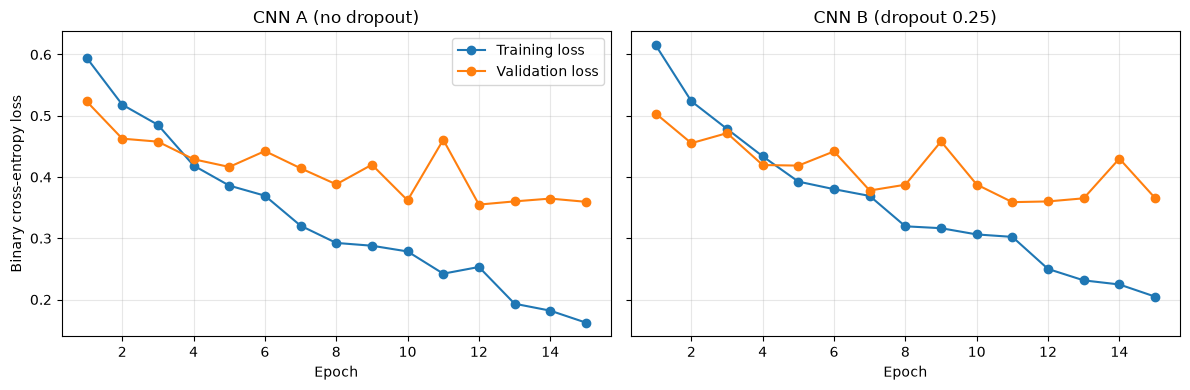

In [9]:
comparison_df = pd.DataFrame([
    baseline_results,
    cnn_a_results,
    cnn_b_results,
])

display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

run_results = [
    ("CNN A (no dropout)", cnn_a_train_loss, cnn_a_val_loss),
    ("CNN B (dropout 0.25)", cnn_b_train_loss, cnn_b_val_loss),
]

for ax, (run_name, train_losses, val_losses) in zip(axes, run_results):
    epochs = np.arange(1, CNN_EPOCHS + 1)
    ax.plot(epochs, train_losses, marker="o", label="Training loss")
    ax.plot(epochs, val_losses, marker="o", label="Validation loss")
    ax.set_title(run_name)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
plt.tight_layout()
plt.show()


### Controlled experiment result

**Expectation (stated before training):** dropout would reduce overfitting and might
improve validation F1, at some risk to recall.

**Result: the expectation was not supported in this run.**

| Validation (n = 195) | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|
| CNN A (dropout 0.0) | 0.8480 | 0.9060 | **0.8760** | 0.8462 |
| CNN B (dropout 0.25) | 0.8333 | 0.8974 | 0.8642 | 0.8308 |

- **Metrics:** CNN B was slightly worse on every validation metric. Its F1 was 0.012
  lower, which is about two predictions on 195 images. It missed one more defect and
  rejected two more acceptable parts (see the selection detail table below).
- **Loss curves:** dropout did what it does mechanically. CNN B's final training loss
  was higher (0.205 vs. 0.162), because dropout makes the training data harder to fit.
  But its validation loss was not lower (0.366 vs. 0.360 at epoch 15). For both runs,
  validation loss falls until about epoch 11-12 and then mostly stays around
  0.36-0.37, while training loss keeps falling. That widening gap is overfitting, and
  dropout 0.25 did not close it.
- **Noise:** validation loss jumps between epochs (CNN A: 0.461 at epoch 11; CNN B:
  0.458 at epoch 9 and 0.430 at epoch 14). Each configuration was trained once with
  one seed, so this experiment cannot show that dropout hurts in general, only that
  0.25 did not help here.
- **Against the baseline:** both CNNs beat logistic regression on validation F1 (0.853)
  and recall (0.846). Logistic regression rejected the fewest acceptable parts (16).

### Validation-only model selection

Select by validation defective-class F1. Break ties in favor of the simpler
model: logistic regression, then CNN A, then CNN B. No test score is inspected
before this point.

In [10]:
selection_candidates = [
    ("Logistic regression", baseline_results["F1"], "baseline"),
    ("CNN A (no dropout)", cnn_a_results["F1"], "cnn_a"),
    ("CNN B (dropout 0.25)", cnn_b_results["F1"], "cnn_b"),
]

best_f1 = max(candidate[1] for candidate in selection_candidates)
tied_candidates = [
    candidate for candidate in selection_candidates
    if np.isclose(candidate[1], best_f1, rtol=0.0, atol=1e-12)
]

selected_name, selected_f1, selected_kind = tied_candidates[0]

if selected_kind == "baseline":
    selected_model = baseline_model
elif selected_kind == "cnn_a":
    selected_model = cnn_a_model
else:
    selected_model = cnn_b_model

print("Validation defective-F1:", round(selected_f1, 4))
print("Selected configuration:", selected_name)
print("Test set: not evaluated")


Validation defective-F1: 0.876
Selected configuration: CNN A (no dropout)
Test set: not evaluated


### Verifying and freezing the selection

These cells check the selection above and then freeze the selected model, so the test
set can only be scored by that model:

1. **Same models, same numbers.** Each configuration's validation predictions are
   recomputed from its fitted model and must reproduce the metrics in the comparison
   table. This confirms that the model objects carried forward are the ones that were
   compared.
2. **Same rule.** The selection rule is applied again independently: highest validation
   F1 for the defective class with P(defective) ≥ 0.5, and ties go to the simpler model
   (logistic regression first, then fewer trainable parameters, then CNN A before CNN B).
   It must pick the same configuration as the cell above.
3. **Frozen.** The selected model's validation predictions are fingerprinted. The test
   evaluation must call `assert_selection_unchanged()`, which fails if the model has been
   changed or retrained since it was selected.

Each CNN uses its weights after the final epoch (epoch 15). No checkpoint is chosen, so
no epoch selection is involved.

In [11]:
DECISION_THRESHOLD = 0.5
DEFECTIVE, ACCEPTABLE = 1, 0


def predict_labels(defect_probabilities):
    """Apply the fixed rule: P(defective) >= 0.5 -> defective (1)."""
    return (np.asarray(defect_probabilities, dtype=np.float64)
            >= DECISION_THRESHOLD).astype(np.int64)


def defect_metrics(y_true, defect_probabilities):
    """Defective-class precision, recall, F1, plus accuracy and error counts."""
    y_pred = predict_labels(defect_probabilities)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[ACCEPTABLE, DEFECTIVE]
    ).ravel()
    return {
        "Precision": precision_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "False negatives": int(fn),
        "False positives": int(fp),
    }


def baseline_predict_proba(images):
    """Prepared images (N, 64, 64) -> P(defective) from the logistic regression."""
    flat = np.asarray(images).reshape(len(images), -1)
    return baseline_model.predict_proba(flat)[:, list(baseline_model.classes_).index(DEFECTIVE)]


def cnn_predict_proba(model, images):
    """Prepared images (N, 64, 64) -> P(defective) from a trained CNN."""
    model.eval()
    with torch.no_grad():
        batch = torch.from_numpy(np.array(images, dtype=np.float32, copy=True)).unsqueeze(1)
        return torch.sigmoid(model(batch.to(device))).cpu().numpy().astype(np.float64)


def count_trainable_parameters(model):
    """Trainable parameters of a PyTorch model or a fitted sklearn linear model."""
    if hasattr(model, "parameters"):
        return int(sum(p.numel() for p in model.parameters() if p.requires_grad))
    return int(model.coef_.size + model.intercept_.size)


candidates = []
for model, results, predict_proba, history in [
    (baseline_model, baseline_results, baseline_predict_proba, None),
    (cnn_a_model, cnn_a_results, partial(cnn_predict_proba, cnn_a_model),
     {"train_loss": cnn_a_train_loss, "val_loss": cnn_a_val_loss}),
    (cnn_b_model, cnn_b_results, partial(cnn_predict_proba, cnn_b_model),
     {"train_loss": cnn_b_train_loss, "val_loss": cnn_b_val_loss}),
]:
    name = results["Configuration"]
    val_probabilities = np.asarray(predict_proba(X_val_images), dtype=np.float64).ravel()
    if val_probabilities.shape != y_val.shape or not (
        np.isfinite(val_probabilities).all()
        and 0 <= val_probabilities.min() <= val_probabilities.max() <= 1
    ):
        raise ValueError(f"{name}: predictions are not one probability per validation image.")

    metrics = defect_metrics(y_val, val_probabilities)
    for metric in ["Precision", "Recall", "F1", "Accuracy"]:
        if not np.isclose(metrics[metric], results[metric], rtol=0, atol=1e-9):
            raise AssertionError(
                f"{name}: recomputed validation {metric} ({metrics[metric]:.4f}) does not "
                f"match the comparison table ({results[metric]:.4f}). The model changed "
                "after it was evaluated."
            )

    candidates.append({
        "name": name,
        "model": model,
        "predict_proba": predict_proba,
        "val_probabilities": val_probabilities,
        "training_seconds": results["Training time (seconds)"],
        "trainable_parameters": count_trainable_parameters(model),
        "selected_epoch": None if history is None else CNN_EPOCHS,
        "history": history,
        **metrics,
    })

# Apply the selection rule again, independent from the cell above.
selection_detail = pd.DataFrame([
    {
        "Configuration": c["name"],
        "F1": c["F1"],
        "False negatives": c["False negatives"],
        "False positives": c["False positives"],
        "Trainable parameters": c["trainable_parameters"],
        "Order": order,
    }
    for order, c in enumerate(candidates)
])
best_f1 = selection_detail["F1"].max()
tied = selection_detail[
    np.isclose(selection_detail["F1"], best_f1, rtol=0, atol=1e-12)
].assign(is_cnn=lambda table: (table["Order"] != 0).astype(int))
rule_winner = tied.sort_values(["is_cnn", "Trainable parameters", "Order"]).iloc[0]

if rule_winner["Configuration"] != selected_name:
    raise AssertionError(
        f"The selection rule picks {rule_winner['Configuration']}, but the cell above "
        f"selected {selected_name}."
    )

selection_detail["Selected"] = np.where(
    selection_detail["Order"] == rule_winner["Order"], "✓", ""
)
display(
    selection_detail.drop(columns="Order").set_index("Configuration")
    .style.format({"F1": "{:.4f}", "Trainable parameters": "{:,}"})
    .set_caption(
        f"Validation set (n = {len(y_val)}): {int((y_val == DEFECTIVE).sum())} defective, "
        f"{int((y_val == ACCEPTABLE).sum())} acceptable. "
        "False negatives = defects accepted; false positives = acceptable parts rejected."
    )
)

print("All recomputed validation metrics match the comparison table.")
if len(tied) > 1:
    print("Tied on F1:", ", ".join(tied["Configuration"]),
          "- tie broken in favor of the simpler model.")
print("Selection rule confirms:", selected_name)

,F1,False negatives,False positives,Trainable parameters,Selected
Configuration,,,,,
Logistic regression,0.8534,18,16,"4,097",
CNN A (no dropout),0.8760,11,19,"2,102,465",✓
CNN B (dropout 0.25),0.8642,12,21,"2,102,465",


All recomputed validation metrics match the comparison table.
Selection rule confirms: CNN A (no dropout)


In [12]:
# Freeze the selection. The test evaluation must use selected_predict_proba
# and call assert_selection_unchanged() before scoring the test set.
selected_candidate = next(c for c in candidates if c["name"] == selected_name)
assert selected_candidate["model"] is selected_model
selected_predict_proba = selected_candidate["predict_proba"]

SELECTION_IS_FINAL = True
missing_candidates = []


def _fingerprint(probabilities):
    return hashlib.sha256(np.round(probabilities, 6).tobytes()).hexdigest()


_selected_fingerprint = _fingerprint(selected_candidate["val_probabilities"])


def assert_selection_unchanged():
    """Fail if the frozen model's validation predictions have changed."""
    current = np.asarray(selected_predict_proba(X_val_images), dtype=np.float64).ravel()
    if _fingerprint(current) != _selected_fingerprint:
        raise RuntimeError(f"{selected_name} has changed since it was selected.")


# Names used by the evaluation section.
cnn_base_candidate, cnn_variant_candidate = candidates[1], candidates[2]
cnn_base_history = cnn_base_candidate["history"]
cnn_variant_history = cnn_variant_candidate["history"]

assert_selection_unchanged()
print("Frozen selection:", selected_name)
print(f"Validation defective-class F1: {selected_candidate['F1']:.4f}")
print("Test set: not evaluated")

Frozen selection: CNN A (no dropout)
Validation defective-class F1: 0.8760
Test set: not evaluated


## Test evaluation and error analysis

The validation comparison table for all three configurations and the training and validation loss curves for both CNN runs appear above, in the CNN section. This section evaluates the frozen selected model on the test set.

The following results use the frozen model from the selection above and the fixed rule P(defective) ≥ 0.5. Nothing is retrained, retuned or reselected after test results are seen, and no model is trained on validation data.

In [13]:
CLASS_NAMES = {ACCEPTABLE: "Acceptable", DEFECTIVE: "Defective"}
MAX_ERROR_EXAMPLES = 6
NUM_CORRECT_EXAMPLES = 2


def metrics_row(name, split_name, y_true, defect_probabilities):
    return {
        "Configuration": name,
        "Split": split_name,
        "Images": len(y_true),
        **defect_metrics(y_true, defect_probabilities),
    }


def plot_confusion_matrix(y_true, y_pred, title):
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=[ACCEPTABLE, DEFECTIVE],
        display_labels=[f"{CLASS_NAMES[c]} ({c})" for c in (ACCEPTABLE, DEFECTIVE)],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[ACCEPTABLE, DEFECTIVE]).ravel()
    print(f"True negatives  (acceptable kept):     {tn}")
    print(f"False positives (acceptable rejected): {fp}")
    print(f"False negatives (defects accepted):    {fn}")
    print(f"True positives  (defects caught):      {tp}")


def choose_error_examples(y_true, y_pred, probabilities, max_examples=MAX_ERROR_EXAMPLES):
    """Up to max_examples errors, covering both types when available.

    Each type gets up to half the slots; unused slots go to the other type. Within a
    type, the most confident mistakes come first (false negatives with the lowest
    P(defective), false positives with the highest). Ties keep filename order.
    """
    index = np.arange(len(y_true))
    false_negatives = index[(y_true == DEFECTIVE) & (y_pred == ACCEPTABLE)]
    false_positives = index[(y_true == ACCEPTABLE) & (y_pred == DEFECTIVE)]
    false_negatives = false_negatives[np.argsort(probabilities[false_negatives], kind="stable")]
    false_positives = false_positives[np.argsort(-probabilities[false_positives], kind="stable")]

    half = max_examples // 2
    n_fn = min(len(false_negatives), max(half, max_examples - len(false_positives)))
    n_fp = min(len(false_positives), max_examples - n_fn)
    return np.concatenate([false_negatives[:n_fn], false_positives[:n_fp]]).astype(int)


def choose_correct_examples(y_true, y_pred, probabilities, count=NUM_CORRECT_EXAMPLES):
    """One confidently correct image per class when possible (defect caught, good part kept)."""
    index = np.arange(len(y_true))
    true_positives = index[(y_true == DEFECTIVE) & (y_pred == DEFECTIVE)]
    true_negatives = index[(y_true == ACCEPTABLE) & (y_pred == ACCEPTABLE)]
    true_positives = true_positives[np.argsort(-probabilities[true_positives], kind="stable")]
    true_negatives = true_negatives[np.argsort(probabilities[true_negatives], kind="stable")]

    chosen = list(true_positives[:1]) + list(true_negatives[:1])
    leftovers = list(true_positives[1:]) + list(true_negatives[1:])
    chosen += leftovers[: max(0, count - len(chosen))]
    return np.array(chosen[:count], dtype=int)


def outcome_name(true_label, predicted_label):
    if true_label == predicted_label:
        return "Correct"
    if true_label == DEFECTIVE:
        return "False negative (defect accepted)"
    return "False positive (acceptable rejected)"


def show_examples(rows, y_true, y_pred, probabilities, indices, title, columns=3):
    """Show the original 512x512 photographs (the model saw 64x64 grayscale versions)."""
    if len(indices) == 0:
        print(f"{title}: none to show.")
        return
    n_rows = int(np.ceil(len(indices) / columns))
    fig, axes = plt.subplots(n_rows, columns, figsize=(4.2 * columns, 4.8 * n_rows),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        relative_path = rows.loc[i, "relative_path"]
        with Image.open(DATA_DIR / relative_path) as image:
            ax.imshow(image.convert("L"), cmap="gray")
        ax.set_title(
            f"{outcome_name(y_true[i], y_pred[i])}\n"
            f"True: {CLASS_NAMES[y_true[i]]} | Predicted: {CLASS_NAMES[y_pred[i]]}\n"
            f"P(defective) = {probabilities[i]:.3f}\n{Path(relative_path).name}",
            fontsize=9,
        )
    fig.suptitle(title)
    plt.show()

### Test-set evaluation of the selected model (run once)

The test images are loaded here for the first time. The selected, frozen model scores
them once with P(defective) ≥ 0.5. The selected model's validation row is shown beside
its test row for reference only; it is not used to change anything.

In [14]:
test_results = None

if not SELECTION_IS_FINAL:
    print("SKIPPED: the selection is provisional (missing: "
          + ", ".join(missing_candidates) + "). The test set has not been loaded.")
else:
    assert_selection_unchanged()  # same frozen model that was selected on validation

    X_test_images, y_test, test_rows = load_image_split("test")
    test_probabilities = np.asarray(selected_predict_proba(X_test_images), dtype=np.float64).ravel()
    test_predictions = predict_labels(test_probabilities)
    assert test_probabilities.shape == y_test.shape

    test_results = {
        "rows": test_rows,
        "y_true": y_test,
        "probabilities": test_probabilities,
        "predictions": test_predictions,
    }

    test_summary = pd.DataFrame([
        metrics_row(selected_name, "Validation (selection)", y_val,
                    selected_candidate["val_probabilities"]),
        metrics_row(selected_name, "Test (final)", y_test, test_probabilities),
    ]).set_index(["Configuration", "Split"])

    display(test_summary.style.format({
        "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}", "Accuracy": "{:.4f}",
    }).set_caption(
        f"Selected model: {selected_name}. Decision rule: P(defective) ≥ {DECISION_THRESHOLD}. "
        "Precision, recall and F1 are for the defective class."
    ))

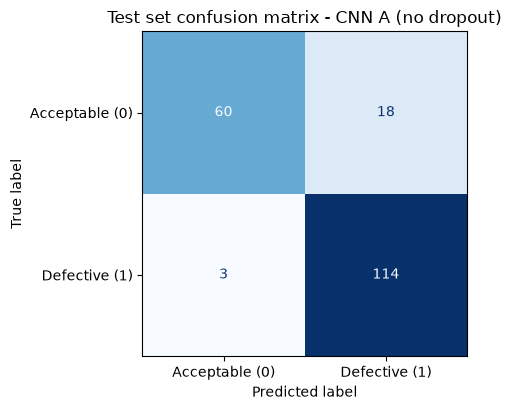

True negatives  (acceptable kept):     60
False positives (acceptable rejected): 18
False negatives (defects accepted):    3
True positives  (defects caught):      114


In [15]:
if test_results is None:
    print("SKIPPED: no test results yet.")
else:
    plot_confusion_matrix(
        test_results["y_true"], test_results["predictions"],
        title=f"Test set confusion matrix - {selected_name}",
    )

### Misclassified and correctly classified test images

Up to six misclassified test images are shown, covering both error types when both occur.
Each type gets up to three slots, and unused slots go to the other type. Within a type the
most confident mistakes come first. Two correctly classified images follow: one defect
that was caught and one acceptable part that was kept. Titles give the true label, the
predicted label and the model's P(defective). The photographs are the 512x512 originals;
the model saw them as 64x64 grayscale.

Showing 6 of 21 misclassified test images.


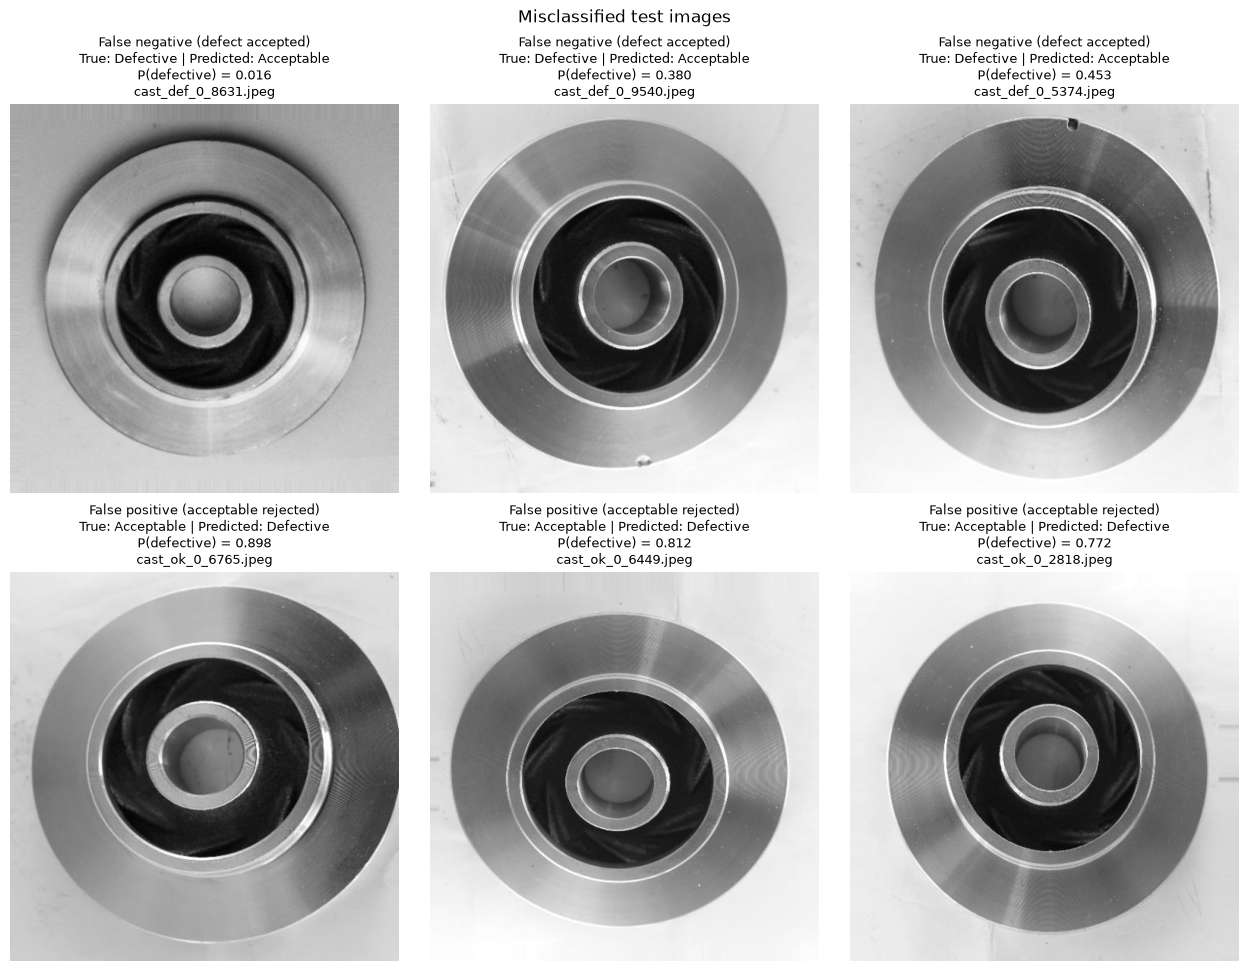

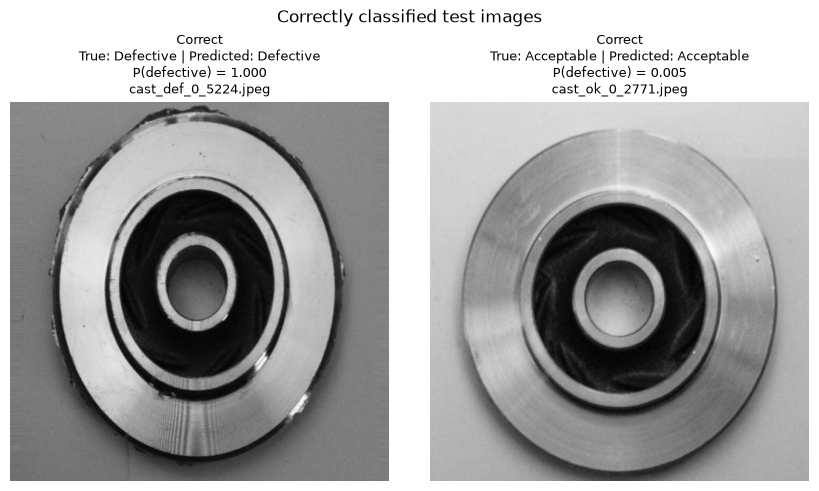

In [16]:
if test_results is None:
    print("SKIPPED: no test results yet.")
else:
    r = test_results
    error_indices = choose_error_examples(r["y_true"], r["predictions"], r["probabilities"])
    total_errors = int((r["y_true"] != r["predictions"]).sum())

    if total_errors == 0:
        print("There are no misclassified images to show.")
    else:
        print(f"Showing {len(error_indices)} of {total_errors} misclassified test images.")
        show_examples(r["rows"], r["y_true"], r["predictions"], r["probabilities"],
                      error_indices, title="Misclassified test images")

    correct_indices = choose_correct_examples(r["y_true"], r["predictions"], r["probabilities"])
    show_examples(r["rows"], r["y_true"], r["predictions"], r["probabilities"],
                  correct_indices, title="Correctly classified test images", columns=2)

## Discussion and limitations

**False negatives vs. false positives** A false positive is when the model predicts that a casting is defective when in reality it is acceptable; this results in a loss of acceptable product. A false negative is when a defective casting is predicted as acceptable, allowing defective parts to continue in production. On the test set the model made 18 false positives and 3 false negatives. In terms of an inspection workflow, false negatives are more impactful. While a false positive has the potential to lose money by removing good castings, a false negative can cause damage to the machines the casting is part of, the casting could fail, and there could be an even larger monetary impact if a recall has to be made. The selected CNN fits that priority: it caught 114 of 117 defective test castings (recall 0.974). The cost is that it rejected 18 of 78 acceptable castings (23%), so in practice flagged parts would need a manual re-check. The decision threshold stayed fixed at 0.5, as required.

**What errors show**

- *Missed defects* Two of the three false negatives were close to the threshold (P(defective) = 0.380 and 0.453). The observable defects are small marks or a notch on the outer rim, which are very small after resizing to 64x64. The third (cast_def_0_8631, P = 0.016) has no apparent defect that is obvious by visually inspecting the image, but its background is a flat gray with faint stripes. So, the model could rely on background or lighting rather than the part itself to some degree.
- *Rejected acceptable parts* The most confident false positives (P = 0.77-0.90) have bright reflections and fine machining lines across the flange. As the image is processed and passed through the model, these characteristics may have been mistaken for actual defects that were seen in other images.

**Validation vs. test** Test F1 (0.916) is higher than validation F1 (0.876). The sample size is low, only 195 images, for both testing and validation sets so a few predictions changing moves F1 noticeably. This is likely sampling variation, not evidence that the model improved as nothing was trained on test data and nothing was changed after the test results were seen.

### Limitations

1. **Controlled photographs from one source** The images in the dataset that the model was trained and tested on only contain one type of part all taken at similar angles in similar lighting. This limited variation means this model should not be directly used for new factories or a new product. In order to be applied to those situations, the model would need to be trained, validated, and tested on images that represent the new factory or product.
2. **Small evaluation sets and a single run** As stated above, the validation and testing sets only contain 195 images (117 defective, 78 acceptable). A change in one prediction can change the defective-class F1 by about 0.005. Additionally, there was only one training done on each configuration so differences between the models are not as clear as they could be.
3. **Unrealistic class balance** The amount of defects in the dataset likely are not representative of actual production lines. Roughly 60% of the images in the dataset are of defective images, if a production line had a 60% defect rate, there would likely be some kind of overhaul or investigation to reduce that number. With a lower percentage of defective parts, the precision would likely be much lower resulting in more acceptable parts being rejected. This change might affect the decision on if the model is acceptable or not.
4. **Low resolution and exact-only duplicate checks** Some of the fine or small defects may have been missed because of the image preprocessing that reduced them to 64x64 grayscale. It is also possible that some images of the same part were used across splits because only exact duplicates were removed so slight variations in images of the same part could have made it through the check.

## Conclusions

- **Selected model** CNN A (two convolutional blocks, no dropout), chosen by validation defective-class F1: 0.876, compared with 0.864 for CNN B (dropout 0.25) and 0.853 for logistic regression.
- **Test results (evaluated once)** precision 0.864, recall 0.974, and F1 0.916 for the defective class and accuracy 0.892. The model missed 3 of 117 defects and rejected 18 of 78 acceptable parts.
- **For inspection** the model catches nearly all defects, which matters most, but about a quarter of acceptable parts would be flagged for re-inspection.
- **Scope:** these results apply to controlled photographs of this one product. Using the model in another factory or on another product would require new data and re-evaluation.